In [1]:
import pandas as pd
import numpy as np

In [2]:
calendar_path = "C:/Users/Admin/OneDrive/Desktop/SalesPulse-AI/data/raw/calendar.csv"

calendar_df = pd.read_csv(calendar_path)

calendar_df["date"] = pd.to_datetime(calendar_df["date"])

print("Shape:", calendar_df.shape)
print(calendar_df.head())

Shape: (1969, 14)
        date  wm_yr_wk    weekday  wday  month  year    d event_name_1  \
0 2011-01-29     11101   Saturday     1      1  2011  d_1          NaN   
1 2011-01-30     11101     Sunday     2      1  2011  d_2          NaN   
2 2011-01-31     11101     Monday     3      1  2011  d_3          NaN   
3 2011-02-01     11101    Tuesday     4      2  2011  d_4          NaN   
4 2011-02-02     11101  Wednesday     5      2  2011  d_5          NaN   

  event_type_1 event_name_2 event_type_2  snap_CA  snap_TX  snap_WI  
0          NaN          NaN          NaN        0        0        0  
1          NaN          NaN          NaN        0        0        0  
2          NaN          NaN          NaN        0        0        0  
3          NaN          NaN          NaN        1        1        0  
4          NaN          NaN          NaN        1        0        1  


In [3]:
calendar_df["year"] = calendar_df["date"].dt.year
calendar_df["month"] = calendar_df["date"].dt.month
calendar_df["day"] = calendar_df["date"].dt.day
calendar_df["day_of_week"] = calendar_df["date"].dt.dayofweek
calendar_df["week_of_year"] = (
    calendar_df["date"].dt.isocalendar().week.astype(int)
)

print(
    calendar_df[
        ["date", "year", "month", "day",
         "day_of_week", "week_of_year"]
    ].head(10)
)

        date  year  month  day  day_of_week  week_of_year
0 2011-01-29  2011      1   29            5             4
1 2011-01-30  2011      1   30            6             4
2 2011-01-31  2011      1   31            0             5
3 2011-02-01  2011      2    1            1             5
4 2011-02-02  2011      2    2            2             5
5 2011-02-03  2011      2    3            3             5
6 2011-02-04  2011      2    4            4             5
7 2011-02-05  2011      2    5            5             5
8 2011-02-06  2011      2    6            6             5
9 2011-02-07  2011      2    7            0             6


In [4]:
calendar_df["is_event_day"] = (
    calendar_df["event_name_1"].notna() |
    calendar_df["event_name_2"].notna()
)

print(
    calendar_df[
        ["date", "event_name_1", "event_name_2", "is_event_day"]
    ].head(20)
)

         date   event_name_1 event_name_2  is_event_day
0  2011-01-29            NaN          NaN         False
1  2011-01-30            NaN          NaN         False
2  2011-01-31            NaN          NaN         False
3  2011-02-01            NaN          NaN         False
4  2011-02-02            NaN          NaN         False
5  2011-02-03            NaN          NaN         False
6  2011-02-04            NaN          NaN         False
7  2011-02-05            NaN          NaN         False
8  2011-02-06      SuperBowl          NaN          True
9  2011-02-07            NaN          NaN         False
10 2011-02-08            NaN          NaN         False
11 2011-02-09            NaN          NaN         False
12 2011-02-10            NaN          NaN         False
13 2011-02-11            NaN          NaN         False
14 2011-02-12            NaN          NaN         False
15 2011-02-13            NaN          NaN         False
16 2011-02-14  ValentinesDay          NaN       

In [5]:
print(calendar_df.columns.tolist())

['date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year', 'd', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI', 'day', 'day_of_week', 'week_of_year', 'is_event_day']


In [6]:
processed_path = "C:/Users/Admin/OneDrive/Desktop/SalesPulse-AI/data/processed/calendar_features.csv"

calendar_df.to_csv(processed_path, index=False)

print("Saved successfully!")
print(processed_path)

Saved successfully!
C:/Users/Admin/OneDrive/Desktop/SalesPulse-AI/data/processed/calendar_features.csv


In [7]:
sales_path = "C:/Users/Admin/OneDrive/Desktop/SalesPulse-AI/data/raw/sales_train_validation.csv"

sales_ids = pd.read_csv(
    sales_path,
    usecols=[
        "id",
        "item_id",
        "dept_id",
        "cat_id",
        "store_id",
        "state_id"
    ]
)

print("Shape:", sales_ids.shape)
print(sales_ids.head())

Shape: (30490, 6)
                              id        item_id    dept_id   cat_id store_id  \
0  HOBBIES_1_001_CA_1_validation  HOBBIES_1_001  HOBBIES_1  HOBBIES     CA_1   
1  HOBBIES_1_002_CA_1_validation  HOBBIES_1_002  HOBBIES_1  HOBBIES     CA_1   
2  HOBBIES_1_003_CA_1_validation  HOBBIES_1_003  HOBBIES_1  HOBBIES     CA_1   
3  HOBBIES_1_004_CA_1_validation  HOBBIES_1_004  HOBBIES_1  HOBBIES     CA_1   
4  HOBBIES_1_005_CA_1_validation  HOBBIES_1_005  HOBBIES_1  HOBBIES     CA_1   

  state_id  
0       CA  
1       CA  
2       CA  
3       CA  
4       CA  


In [8]:
sales_data = pd.read_csv(
    sales_path,
    usecols=lambda col: col.startswith("d_")
)

print("Shape:", sales_data.shape)

Shape: (30490, 1913)


In [9]:
sales_data

,d_1,d_2,d_3,d_4,d_5,d_6,d_7,d_8,d_9,d_10,...,d_1904,d_1905,d_1906,d_1907,d_1908,d_1909,d_1910,d_1911,d_1912,d_1913
0,0,0,0,0,0,0,0,0,0,0,...,1,3,0,1,1,1,3,0,1,1
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,2,1,2,1,1,1,0,1,1,1
3,0,0,0,0,0,0,0,0,0,0,...,1,0,5,4,1,0,1,3,7,2
4,0,0,0,0,0,0,0,0,0,0,...,2,1,1,0,1,1,2,2,2,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30485,0,0,2,2,0,3,1,4,1,0,...,2,0,0,0,0,0,1,0,0,1
30486,0,0,0,0,0,5,0,1,1,3,...,0,0,0,0,0,0,0,0,1,0
30487,0,6,0,2,2,4,1,8,5,2,...,2,1,0,2,0,1,0,0,1,0
30488,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,1,0,3,1,3


In [10]:
row_total_sales = sales_data.sum(axis=1)

print(row_total_sales.head())

0     600
1     493
2     288
3    3288
4    1849
dtype: int64


In [11]:
daily_sales_target = sales_data.sum(axis=0)

print("Number of days:", len(daily_sales_target))
print(daily_sales_target.head())

Number of days: 1913
d_1    32631
d_2    31749
d_3    23783
d_4    25412
d_5    19146
dtype: int64


In [12]:
daily_target = pd.DataFrame({
    "d": daily_sales_target.index,
    "total_sales": daily_sales_target.values
})

print(daily_target.head())
print(daily_target.shape)

     d  total_sales
0  d_1        32631
1  d_2        31749
2  d_3        23783
3  d_4        25412
4  d_5        19146
(1913, 2)


In [41]:
model_data = calendar_df.merge(
    daily_target,
    on="d",
    how="inner"
)
model_data["date"] = pd.to_datetime(model_data["date"])
print("Shape:", model_data.shape)
print(model_data.head())

Shape: (1913, 19)
        date  wm_yr_wk    weekday  wday  month  year    d event_name_1  \
0 2011-01-29     11101   Saturday     1      1  2011  d_1          NaN   
1 2011-01-30     11101     Sunday     2      1  2011  d_2          NaN   
2 2011-01-31     11101     Monday     3      1  2011  d_3          NaN   
3 2011-02-01     11101    Tuesday     4      2  2011  d_4          NaN   
4 2011-02-02     11101  Wednesday     5      2  2011  d_5          NaN   

  event_type_1 event_name_2 event_type_2  snap_CA  snap_TX  snap_WI  day  \
0          NaN          NaN          NaN        0        0        0   29   
1          NaN          NaN          NaN        0        0        0   30   
2          NaN          NaN          NaN        0        0        0   31   
3          NaN          NaN          NaN        1        1        0    1   
4          NaN          NaN          NaN        1        0        1    2   

   day_of_week  week_of_year  is_event_day  total_sales  
0            5        

In [14]:
features = [
    "year",
    "month",
    "day",
    "day_of_week",
    "week_of_year",
    "is_event_day"
]

X = model_data[features]
y = model_data["total_sales"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print(X.head())
print(y.head())

X shape: (1913, 6)
y shape: (1913,)
   year  month  day  day_of_week  week_of_year  is_event_day
0  2011      1   29            5             4         False
1  2011      1   30            6             4         False
2  2011      1   31            0             5         False
3  2011      2    1            1             5         False
4  2011      2    2            2             5         False
0    32631
1    31749
2    23783
3    25412
4    19146
Name: total_sales, dtype: int64


In [15]:
train_mask = model_data["date"] < "2015-01-01"

validation_mask = (
    (model_data["date"] >= "2015-01-01") &
    (model_data["date"] < "2016-01-01")
)

test_mask = model_data["date"] >= "2016-01-01"


X_train = X[train_mask]
y_train = y[train_mask]

X_val = X[validation_mask]
y_val = y[validation_mask]

X_test = X[test_mask]
y_test = y[test_mask]


print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (1433, 6)
Validation: (365, 6)
Test: (115, 6)


In [16]:
from sklearn.ensemble import RandomForestRegressor

In [17]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [18]:
y_val_pred = rf_model.predict(X_val)

print("First 10 predictions:")
print(y_val_pred[:10])

First 10 predictions:
[25391.65 37730.44 46709.85 44706.06 32273.79 31629.6  31306.77 32546.32
 33474.46 45957.15]


In [19]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(y_val, y_val_pred)

rmse = np.sqrt(
    mean_squared_error(y_val, y_val_pred)
)

print("Validation MAE:", mae)
print("Validation RMSE:", rmse)

Validation MAE: 2523.986136986301
Validation RMSE: 3424.3309312052133


In [22]:
y_val

1433    26452
1434    39633
1435    41085
1436    39647
1437    34691
        ...  
1793    35378
1794    29964
1795    31893
1796    34127
1797    43059
Name: total_sales, Length: 365, dtype: int64

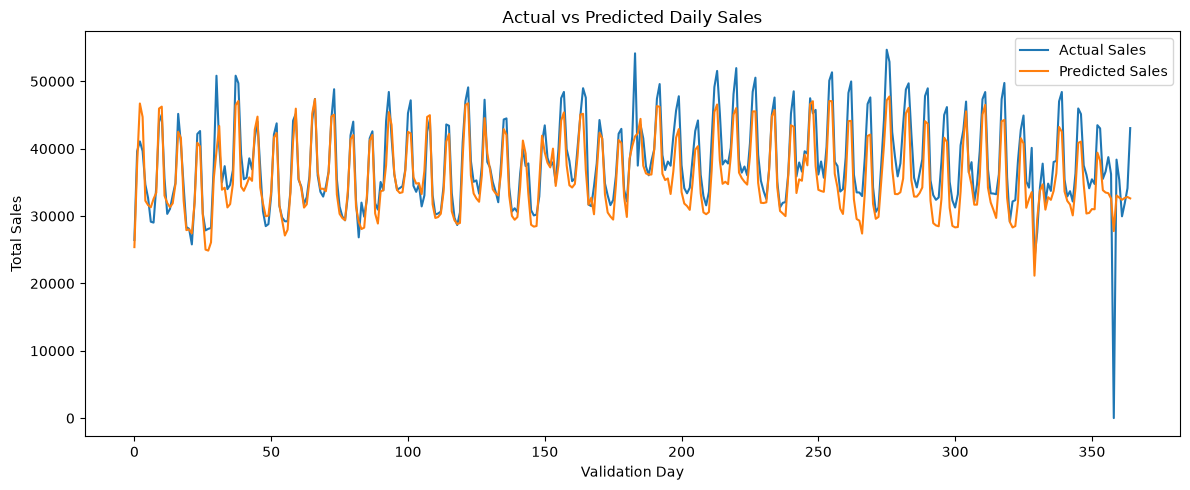

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    y_val.values,
    label="Actual Sales"
)

plt.plot(
    y_val_pred,
    label="Predicted Sales"
)

plt.xlabel("Validation Day")
plt.ylabel("Total Sales")
plt.title("Actual vs Predicted Daily Sales")

plt.legend()
plt.tight_layout()
plt.show()

In [42]:
model_data["lag_1"] = model_data["total_sales"].shift(1)

print(
    model_data[
        ["date", "total_sales", "lag_1"]
    ].head(10)
)

        date  total_sales    lag_1
0 2011-01-29        32631      NaN
1 2011-01-30        31749  32631.0
2 2011-01-31        23783  31749.0
3 2011-02-01        25412  23783.0
4 2011-02-02        19146  25412.0
5 2011-02-03        29211  19146.0
6 2011-02-04        28010  29211.0
7 2011-02-05        37932  28010.0
8 2011-02-06        32736  37932.0
9 2011-02-07        25572  32736.0


In [43]:
model_data["lag_7"] = model_data["total_sales"].shift(7)

print(
    model_data[
        ["date", "total_sales", "lag_1", "lag_7"]
    ].head(15)
)

         date  total_sales    lag_1    lag_7
0  2011-01-29        32631      NaN      NaN
1  2011-01-30        31749  32631.0      NaN
2  2011-01-31        23783  31749.0      NaN
3  2011-02-01        25412  23783.0      NaN
4  2011-02-02        19146  25412.0      NaN
5  2011-02-03        29211  19146.0      NaN
6  2011-02-04        28010  29211.0      NaN
7  2011-02-05        37932  28010.0  32631.0
8  2011-02-06        32736  37932.0  31749.0
9  2011-02-07        25572  32736.0  23783.0
10 2011-02-08        23071  25572.0  25412.0
11 2011-02-09        23658  23071.0  19146.0
12 2011-02-10        23756  23658.0  29211.0
13 2011-02-11        26445  23756.0  28010.0
14 2011-02-12        34833  26445.0  37932.0


In [44]:
model_data["lag_14"] = model_data["total_sales"].shift(14)

print(
    model_data[
        ["date", "total_sales", "lag_1", "lag_7", "lag_14"]
    ].head(20)
)

         date  total_sales    lag_1    lag_7   lag_14
0  2011-01-29        32631      NaN      NaN      NaN
1  2011-01-30        31749  32631.0      NaN      NaN
2  2011-01-31        23783  31749.0      NaN      NaN
3  2011-02-01        25412  23783.0      NaN      NaN
4  2011-02-02        19146  25412.0      NaN      NaN
5  2011-02-03        29211  19146.0      NaN      NaN
6  2011-02-04        28010  29211.0      NaN      NaN
7  2011-02-05        37932  28010.0  32631.0      NaN
8  2011-02-06        32736  37932.0  31749.0      NaN
9  2011-02-07        25572  32736.0  23783.0      NaN
10 2011-02-08        23071  25572.0  25412.0      NaN
11 2011-02-09        23658  23071.0  19146.0      NaN
12 2011-02-10        23756  23658.0  29211.0      NaN
13 2011-02-11        26445  23756.0  28010.0      NaN
14 2011-02-12        34833  26445.0  37932.0  32631.0
15 2011-02-13        36380  34833.0  32736.0  31749.0
16 2011-02-14        21804  36380.0  25572.0  23783.0
17 2011-02-15        24070  

In [45]:
model_data["lag_28"] = model_data["total_sales"].shift(28)

print(
    model_data[
        ["date", "total_sales", "lag_1", "lag_7", "lag_14", "lag_28"]
    ].head(35)
)

         date  total_sales    lag_1    lag_7   lag_14   lag_28
0  2011-01-29        32631      NaN      NaN      NaN      NaN
1  2011-01-30        31749  32631.0      NaN      NaN      NaN
2  2011-01-31        23783  31749.0      NaN      NaN      NaN
3  2011-02-01        25412  23783.0      NaN      NaN      NaN
4  2011-02-02        19146  25412.0      NaN      NaN      NaN
5  2011-02-03        29211  19146.0      NaN      NaN      NaN
6  2011-02-04        28010  29211.0      NaN      NaN      NaN
7  2011-02-05        37932  28010.0  32631.0      NaN      NaN
8  2011-02-06        32736  37932.0  31749.0      NaN      NaN
9  2011-02-07        25572  32736.0  23783.0      NaN      NaN
10 2011-02-08        23071  25572.0  25412.0      NaN      NaN
11 2011-02-09        23658  23071.0  19146.0      NaN      NaN
12 2011-02-10        23756  23658.0  29211.0      NaN      NaN
13 2011-02-11        26445  23756.0  28010.0      NaN      NaN
14 2011-02-12        34833  26445.0  37932.0  32631.0  

In [28]:
model_data = model_data.dropna()

In [46]:
model_data["rolling_mean_7"] =(
    model_data["total_sales"]
    .shift(1)
    .rolling(window=7)
    .mean()
    
)

print(model_data[["date", "total_sales", "rolling_mean_7"]].head(10))

        date  total_sales  rolling_mean_7
0 2011-01-29        32631             NaN
1 2011-01-30        31749             NaN
2 2011-01-31        23783             NaN
3 2011-02-01        25412             NaN
4 2011-02-02        19146             NaN
5 2011-02-03        29211             NaN
6 2011-02-04        28010             NaN
7 2011-02-05        37932    27134.571429
8 2011-02-06        32736    27891.857143
9 2011-02-07        25572    28032.857143


In [47]:
model_data["rolling_mean_28"] = (
    model_data["total_sales"]
    .shift(1)
    .rolling(window=28)
    .mean()
)

print(
    model_data[
        [
            "date",
            "total_sales",
            "rolling_mean_7",
            "rolling_mean_28"
        ]
    ].tail(10)
)

           date  total_sales  rolling_mean_7  rolling_mean_28
1903 2016-04-15        41789    43947.714286     42059.714286
1904 2016-04-16        48362    43743.285714     42136.035714
1905 2016-04-17        51640    42603.571429     42213.928571
1906 2016-04-18        38059    42287.000000     42350.178571
1907 2016-04-19        37570    41663.000000     42375.142857
1908 2016-04-20        35343    41448.857143     42449.964286
1909 2016-04-21        35033    41470.285714     42469.857143
1910 2016-04-22        40517    41113.714286     42506.642857
1911 2016-04-23        48962    40932.000000     42324.714286
1912 2016-04-24        49795    41017.714286     42149.678571


In [32]:
lag_features = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28"
]

print(model_data[lag_features].isnull().sum())

lag_1              0
lag_7              0
lag_14             0
lag_28             0
rolling_mean_7     4
rolling_mean_28    4
dtype: int64


In [48]:
lag_features = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28"
]

model_data = model_data.dropna(
    subset=lag_features
).copy()

print("Rows after cleaning:", len(model_data))
print("Start date:", model_data["date"].min())
print("End date:", model_data["date"].max())

Rows after cleaning: 1885
Start date: 2011-02-26 00:00:00
End date: 2016-04-24 00:00:00


In [49]:
improved_features = [
    "year",
    "month",
    "day",
    "day_of_week",
    "week_of_year",
    "is_event_day",
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28"
]

X_improved = model_data[improved_features]
y_improved = model_data["total_sales"]

print("X shape:", X_improved.shape)
print("y shape:", y_improved.shape)

X shape: (1885, 12)
y shape: (1885,)


In [50]:
train_mask = model_data["date"] < "2015-01-01"

validation_mask = (
    (model_data["date"] >= "2015-01-01") &
    (model_data["date"] < "2016-01-01")
)

test_mask = model_data["date"] >= "2016-01-01"


X_train_imp = X_improved[train_mask]
y_train_imp = y_improved[train_mask]

X_val_imp = X_improved[validation_mask]
y_val_imp = y_improved[validation_mask]

X_test_imp = X_improved[test_mask]
y_test_imp = y_improved[test_mask]


print("Training:", X_train_imp.shape)
print("Validation:", X_val_imp.shape)
print("Test:", X_test_imp.shape)

Training: (1405, 12)
Validation: (365, 12)
Test: (115, 12)


In [51]:
rf_improved = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_improved.fit(X_train_imp, y_train_imp)

print("Improved model training completed!")

Improved model training completed!


In [52]:
y_val_pred_imp = rf_improved.predict(X_val_imp)

print("First 10 predictions:")
print(y_val_pred_imp[:10])

First 10 predictions:
[26956.15 34367.22 43311.52 43231.39 32921.08 32619.5  32477.21 25095.49
 35367.07 42185.48]


In [53]:
mae_imp = mean_absolute_error(
    y_val_imp,
    y_val_pred_imp
)

rmse_imp = np.sqrt(
    mean_squared_error(
        y_val_imp,
        y_val_pred_imp
    )
)

print("Improved Validation MAE:", mae_imp)
print("Improved Validation RMSE:", rmse_imp)

Improved Validation MAE: 1978.4252602739725
Improved Validation RMSE: 3143.3993228498034


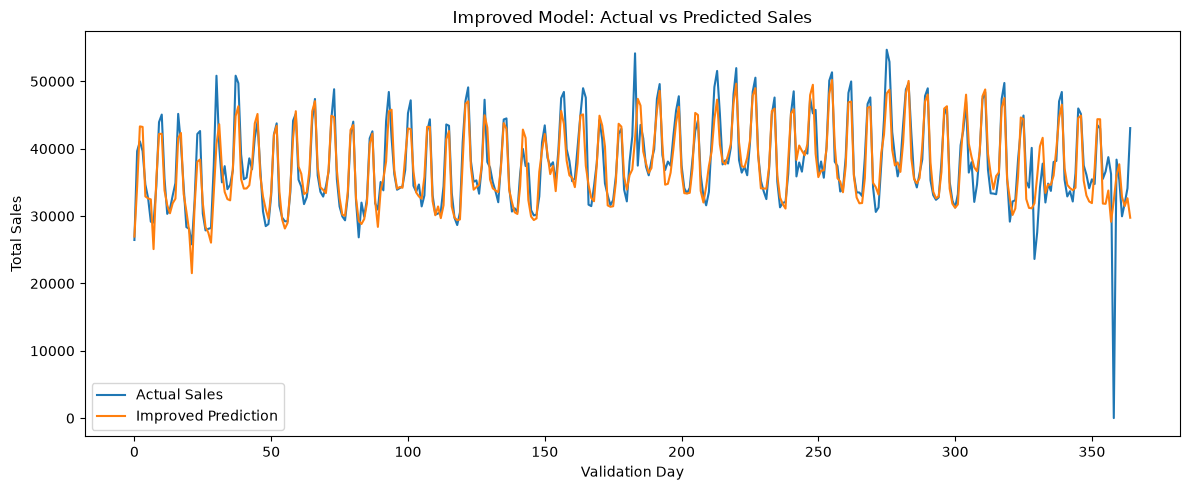

In [54]:
plt.figure(figsize=(12, 5))

plt.plot(
    y_val_imp.values,
    label="Actual Sales"
)

plt.plot(
    y_val_pred_imp,
    label="Improved Prediction"
)

plt.xlabel("Validation Day")
plt.ylabel("Total Sales")
plt.title("Improved Model: Actual vs Predicted Sales")

plt.legend()
plt.tight_layout()
plt.show()

In [55]:
y_test_pred_imp = rf_improved.predict(X_test_imp)

test_mae = mean_absolute_error(
    y_test_imp,
    y_test_pred_imp
)

test_rmse = np.sqrt(
    mean_squared_error(
        y_test_imp,
        y_test_pred_imp
    )
)

print("Test MAE:", test_mae)
print("Test RMSE:", test_rmse)

Test MAE: 2549.880521739131
Test RMSE: 3377.0482115565646


In [57]:
important_feature = pd.Series(
    rf_improved.feature_importances_,
    index=improved_features
).sort_values(ascending=False)

print("Feature Importances:")
print(important_feature)

Feature Importances:
lag_28             0.699641
lag_7              0.071904
day                0.043664
rolling_mean_7     0.036206
lag_1              0.034837
day_of_week        0.030796
lag_14             0.030269
week_of_year       0.019530
rolling_mean_28    0.011970
is_event_day       0.009027
month              0.008319
year               0.003838
dtype: float64


In [58]:
print(
    model_data["total_sales"]
    .corr(model_data["lag_28"])
)

0.8403482854271738


In [59]:
lag_features = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28"
]

correlations = (
    model_data[["total_sales"] + lag_features]
    .corr()["total_sales"]
    .drop("total_sales")
    .sort_values(ascending=False)
)

print(correlations)

lag_28             0.840348
lag_7              0.809732
lag_14             0.742214
lag_1              0.670048
rolling_mean_7     0.612209
rolling_mean_28    0.592537
Name: total_sales, dtype: float64


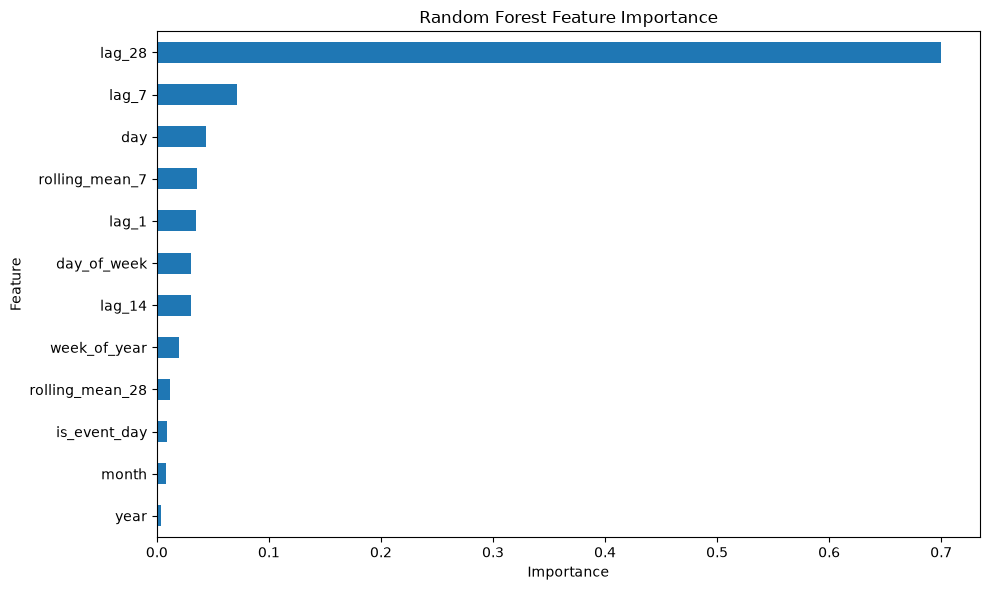

In [60]:
plt.figure(figsize=(10, 6))

important_feature.sort_values().plot(kind="barh")

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.tight_layout()
plt.show()

In [61]:
import joblib

joblib.dump(
    rf_improved,
    "salespulse_rf_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [62]:
joblib.dump(
    improved_features,
    "salespulse_features.pkl"
)

print("Feature list saved successfully!")

Feature list saved successfully!


In [65]:
def predict_sales(features):
    features_df = pd.DataFrame(
        [features],
        columns= rf_improved
    )

    prediction =  rf_improved.predict(features_df)

    return prediction[0]

In [1]:
sample_features = X_val_imp.iloc[0].values

predicted_sales = predict_sales(sample_features)

print("Predicted Sales:", predicted_sales)
print("Actual Sales:", y_val_imp.iloc[0])

NameError: name 'X_val_imp' is not defined